<a href="https://colab.research.google.com/github/freyebeans/ASU-assignments/blob/main/MAT422/HW2.3/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 Section 2.3 Joint Distributions, Depndence and Sampling
Michael Bishop

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(514)

## 2.3.1 Joint Probability Distributions
A joint probability distribution is a probability distribution for multiple random variables. The random variables may or may not be independent.

In [2]:
joint = np.array([[0.1,0.3,0.1,0.1],
                  [0.05,0.2,0.1,0.05]])

px = joint.sum(axis=1)
py = joint.sum(axis=0)
print("Joint total =", joint.sum())
print("P(X) =", px)
print("P(Y) =", py)
print("P(Y = 1) =", py[1])
print("P(X = 1 | Y = 1) =", joint[1,1] / py[1])
print("P(X = 1 and Y = 1) =", joint[1,1])

Joint total = 1.0
P(X) = [0.6 0.4]
P(Y) = [0.15 0.5  0.2  0.15]
P(Y = 1) = 0.5
P(X = 1 | Y = 1) = 0.4
P(X = 1 and Y = 1) = 0.2


In the above code, I used 2 discrete random variables, *X* and *Y*, who are not independent. In that case the joint probability distribution is a joint PMF *p* defined by $p(x,y)=P(X=x\text{ and }Y=y)$. Since X and Y are not independent, $P(X=x\text{ and }Y=y)=P(X=x|Y=y)\cdot P(Y=y)$, which we can see is true above (0.5 * 0.4 = 0.2).
## 2.3.2 Correlation and Dependence
Provided 2 random variables *X* and *Y*, we can compute the covariance $\text{Cov}(X,Y)=E[(X-\mu _X)(Y-\mu _Y)]$, which measures joint variability, and the correlation coefficient $\rho=\frac{\text{Cov}(X,Y)}{\sigma _X \cdot\sigma _Y}$, which measures how closely the variable correlate linearly. If *X* and *Y* are independent $\rho$ = 0.

Corr(X, dependent Y (positive)) = 0.9965480966528768
Corr(X, dependent Y (negative)) = -0.9724266067492873
Corr(X, independent Y) = 0.053902815069524886


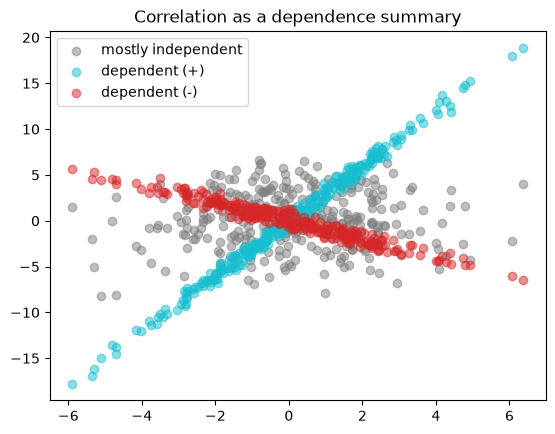

In [3]:
x = rng.normal(0,2,300)
y_p_dep = 3 * x + rng.normal(0,0.5, 300)
y_n_dep = -x + rng.normal(0,0.5, 300)
y_indep = rng.normal(0,3,300)

print("Corr(X, dependent Y (positive)) =", np.corrcoef(x, y_p_dep)[0,1])
print("Corr(X, dependent Y (negative)) =", np.corrcoef(x, y_n_dep)[0,1])
print("Corr(X, independent Y) =", np.corrcoef(x, y_indep)[0,1])

plt.scatter(x, y_indep, alpha=0.5, label="mostly independent", color="tab:gray")
plt.scatter(x, y_p_dep, alpha=0.5, label="dependent (+)", color="tab:cyan")
plt.scatter(x, y_n_dep, alpha=0.5, label="dependent (-)", color="tab:red")
plt.legend()
plt.title("Correlation as a dependence summary")
plt.show()

As you can see in the above diagram and output the correlation coefficient $\rho$ is near 0 for the sampling of the independent random variable, but is near one or negative one for the dependent random variables. Additionally, for the *Y* that increases as *X* increases $\rho$ is close to 1 and for the *Y* that decreases as *X* increases $\rho$ is close to -1.
## 2.3.3 Random Samples
A random sample is a subset of a population that has be selected randomly. These are useful to get an idea of the population, like the mean of the population, and in practice are often used instead of the whole population. According to the central limit theorm, if the distribution being sampled has mean $\mu$ and standard deviation $\sigma$, the distribution of sample means $\bar{X}$ with samples of size *n* is approximately normal and has a mean $\mu _{\bar{X}}$ and standard deviation $\sigma _{\bar{X}}$ such that $\mu _{\bar{X}} = \mu$ and $\sigma _{\bar{X}}^2 = \sigma^2/n$ or $\sigma _{\bar{X}} = \frac{\sigma}{\sqrt{n}}$.

Mean of distribution = 0.6666666666666666
Standard deviation of distribution = 0.23570226039551587
Standard deviation of distribution / sqrt(n) = 0.037267799624996496

Mean of sample means = 0.6658361501232876
Standard deviation of sample means = 0.03736032305944828


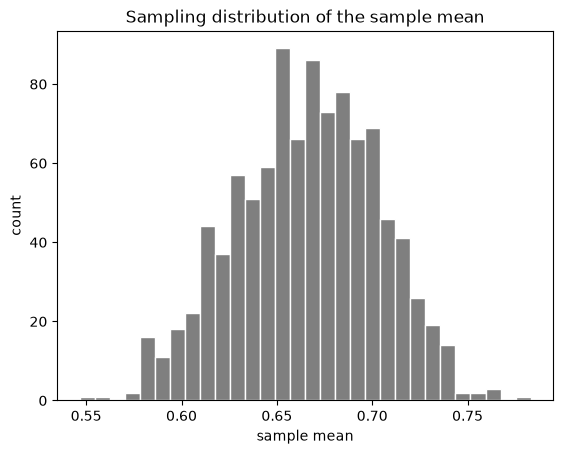

In [4]:
print("Mean of distribution =", 2/3)
print("Standard deviation of distribution =", 1/np.sqrt(18))
print("Standard deviation of distribution / sqrt(n) =", 1/(np.sqrt(18 * 40)))
print()

sample_means = []
for i in range(1000):
    sample = np.sqrt(rng.uniform(0,1,40))
    sample_means.append(sample.mean())

sample_means = np.array(sample_means)
print("Mean of sample means =", sample_means.mean())
print("Standard deviation of sample means =", sample_means.std())

plt.hist(sample_means, bins=30, color="tab:gray", edgecolor="white")
plt.title("Sampling distribution of the sample mean")
plt.xlabel("sample mean")
plt.ylabel("count")
plt.show()

As you can see above the sample of the sample mean distibution is similar in shape to a normal distribution indicating it is approximately normal, and the mean and standard deviation for the sample are close in value to what we calculated the true mean and stdev of the sample mean distribution to be. As you can see, from this random sample we can get an idea of what the true distribution looks like.
## Reflection and Rubric Checklist
- I explained each concpet before and after the code.
- I verifed important claims numerically or visually.
- I changed and extended at least one example so that the notebook reflects my own work.
- I ran the notebook in its entirety without error.
- I saved the notebook from Google Colab directly to GitHub as per course instructions.